# Algoritmo genético — Treinamento do T2

Este notebook acompanha a população, os operadores e o treinamento dos pesos da rede. Ele fica junto de `genetico.py`, como na organização do T1.

A MLP e o Minimax têm notebooks próprios nas suas pastas. Aqui usamos esses componentes para avaliar os indivíduos. As classes e funções do AG aparecem em células de código abaixo.

No VS Code, selecione o kernel da `.venv` e execute na ordem. As primeiras células mostram o experimento salvo, e depois começa outro treinamento. Instale as dependências na raiz do projeto com:

```bash
python3 -m pip install -r t2/apoio/requirements-notebook.txt
```

Os arquivos `.py` continuam sendo usados pelo Flask. Alterar a implementação nas células não modifica automaticamente esses arquivos.

In [1]:
from pathlib import Path
from dataclasses import dataclass, asdict
import sys
import json
from html import escape
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display

# O notebook pode ser aberto pela raiz do repositório ou pela pasta t2.
pasta_atual = Path.cwd().resolve()
raiz = next((p for p in [pasta_atual, *pasta_atual.parents] if (p / "t2" / "app.py").is_file()), None)
if raiz is None:
    raise FileNotFoundError("Abra o notebook dentro da pasta do repositório.")
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from t2.algoritmos.mlp.mlp import Network
from t2.apoio.treinamento import REWARDS, evaluate, play

print("Projeto:", raiz.name)
import csv
pasta_algoritmo = raiz / "t2" / "algoritmos" / "genetico"

def salvar_grafico(figura, nome):
    # O gráfico fica no notebook e também na pasta do algoritmo, como no T1.
    figura.savefig(pasta_algoritmo / nome, dpi=150, bbox_inches="tight")

def salvar_csv(nome, linhas):
    with (pasta_algoritmo / nome).open("w", newline="", encoding="utf-8") as arquivo:
        escritor = csv.DictWriter(arquivo, fieldnames=list(linhas[0]))
        escritor.writeheader()
        escritor.writerows(linhas)


Projeto: t2-organizado


In [2]:
def mostrar_tabela(colunas, linhas):
    cabecalho = "".join(f"<th style='padding:8px;text-align:left'>{escape(str(c))}</th>" for c in colunas)
    corpo = "".join("<tr>" + "".join(f"<td style='padding:8px;border-top:1px solid #ddd'>{escape(str(v))}</td>" for v in linha) + "</tr>" for linha in linhas)
    display(HTML(f"<table><thead><tr>{cabecalho}</tr></thead><tbody>{corpo}</tbody></table>"))


def mostrar_evolucao(historico, nome_arquivo):
    geracoes = [h["generation"] for h in historico]
    fig, eixos = plt.subplots(1, 2, figsize=(11, 3.5))
    eixos[0].plot(geracoes, [h["best"] for h in historico], label="Melhor aptidão")
    eixos[0].plot(geracoes, [h["mean"] for h in historico], label="Média da população")
    eixos[0].set(xlabel="Geração", ylabel="Aptidão")
    eixos[0].legend()
    eixos[1].plot(geracoes, [100*h["valid_rate"] for h in historico])
    eixos[1].set(xlabel="Geração", ylabel="Escolhas válidas da melhor rede (%)", ylim=(0, 100))
    inicio_dificil = next((h["generation"] for h in historico if h["phase"] == "medio+dificil"), None)
    if inicio_dificil is not None:
        for eixo in eixos:
            eixo.axvline(inicio_dificil, color="gray", linestyle="--", linewidth=1)
    fig.tight_layout()
    salvar_grafico(fig, nome_arquivo)
    plt.show()
    plt.close(fig)

## Experimento que já está no projeto

Podemos consultar o treino salvo antes de executar outro. Os arquivos abaixo são os mesmos usados no relatório: população de 80, camada oculta com 9 neurônios, 250 gerações e semente 42. A linha pontilhada no gráfico marca a entrada das partidas no difícil.

A aptidão muda de conjunto de avaliação nessa passagem de fase. Por isso, uma diferença na curva nesse ponto não deve ser lida automaticamente como piora ou melhora da rede.

Parâmetro,Valor
population,80
hidden,9
generations,250
medium_games,24
elite,2
tournament,2
mutation,0.08
sigma,0.2
alpha,0.5
patience,60


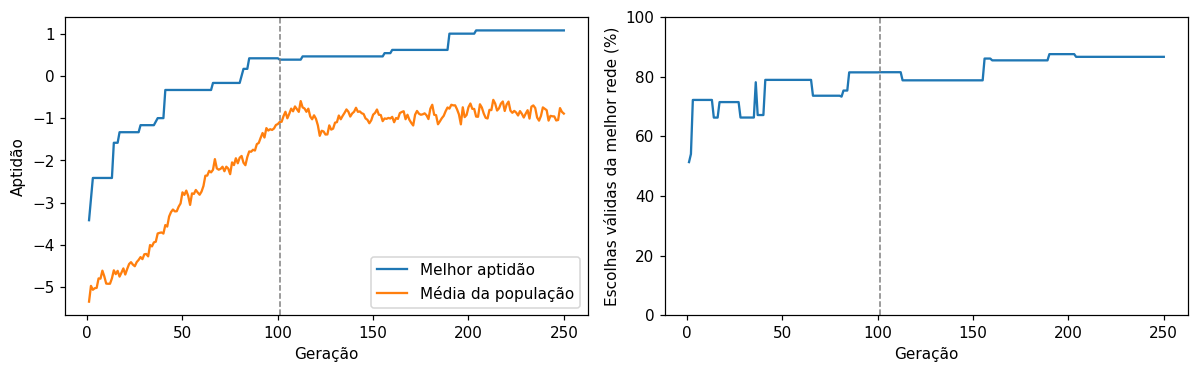

Teste médio: 100 partidas,Primeira geração,Última geração
Vitórias,34,64
Empates,13,21
Derrotas,53,15
Acurácia de decisões,36.6%,77.9%
Escolhas válidas,50.8%,82.4%
Escolhas ocupadas,164,62


In [3]:
arquivo_rede = raiz / "t2" / "algoritmos" / "genetico" / "rede-t2.json"
arquivo_avaliacao = raiz / "t2" / "algoritmos" / "genetico" / "avaliacao.json"
rede_salva = json.loads(arquivo_rede.read_text())
avaliacao_salva = json.loads(arquivo_avaliacao.read_text())
mostrar_tabela(["Parâmetro", "Valor"], list(rede_salva["config"].items()))
mostrar_evolucao(rede_salva["history"], "genetico_evolucao_experimento.png")

antes = avaliacao_salva["baseline"]["medium"]
depois = avaliacao_salva["final"]["medium"]
mostrar_tabela(["Teste médio: 100 partidas", "Primeira geração", "Última geração"], [
    ["Vitórias", antes["vitoria"], depois["vitoria"]],
    ["Empates", antes["empate"], depois["empate"]],
    ["Derrotas", antes["derrota"], depois["derrota"]],
    ["Acurácia de decisões", f'{100*antes["accuracy"]:.1f}%', f'{100*depois["accuracy"]:.1f}%'],
    ["Escolhas válidas", f'{100*antes["valid_rate"]:.1f}%', f'{100*depois["valid_rate"]:.1f}%'],
    ["Escolhas ocupadas", antes["invalid"], depois["invalid"]],
])

## Implementação do algoritmo genético

Estas são as definições usadas neste notebook. O código corresponde ao arquivo `genetico.py`: configuração, cruzamento e ciclo da população. Vamos executar as definições antes de montar o experimento.

In [4]:
@dataclass
class Config:
    population: int = 80
    hidden: int = 9
    generations: int = 250
    medium_games: int = 24
    elite: int = 2
    tournament: int = 2
    mutation: float = .08
    sigma: float = .20
    alpha: float = .5
    patience: int = 60
    seed: int = 42

    def validate(self):
        ranges = {'population':(4,400), 'hidden':(1,64), 'generations':(2,3000),
                  'medium_games':(2,200), 'elite':(1,self.population-1),
                  'tournament':(2,self.population), 'patience':(2,3000), 'seed':(0,2**31-1)}
        for k,(low,high) in ranges.items():
            v = getattr(self,k)
            if type(v) is not int or not low <= v <= high:
                raise ValueError(f'{k}: use inteiro entre {low} e {high}.')
        for k,low,high in [('mutation',0,1),('sigma',.001,1),('alpha',0,1)]:
            v = getattr(self,k)
            if isinstance(v,bool) or not isinstance(v,(int,float)) or not np.isfinite(v) or not low <= v <= high:
                raise ValueError(f'{k}: valor fora do intervalo {low} a {high}.')
        if self.medium_games % 2:
            raise ValueError('Use número par de partidas para equilibrar quem começa.')

In [5]:
def crossover(a, b, rng, alpha):
    # No BLX-alpha, cada gene recebe seu próprio beta, sorteado no intervalo
    # [-alpha, 1+alpha]. A combinação pode gerar um peso diferente dos dois
    # pais, em vez de só copiar um dos valores que já existiam.
    beta = rng.uniform(-alpha,1+alpha,len(a))
    return np.clip(a + beta*(b-a), -1, 1)

In [6]:
class Trainer:
    def __init__(self, config):
        config.validate()
        self.config = config
        self.rng = np.random.default_rng(config.seed)
        self.population = self.rng.uniform(-1,1,(config.population, Network.size(config.hidden)))
        self.generation = 0
        self.history, self.ranked = [], []
        self.best = None
        self.best_fitness = float('-inf')
        self.stagnant, self.previous_phase = 0, None
        self.stopped = None

    def step(self):
        if self.stopped:
            return self.state()
        c = self.config
        hard = self.generation >= max(1,int(c.generations*.4))
        phase = 'medio+dificil' if hard else 'medio'
        # Quando entra o modo difícil, o conjunto de partidas da avaliação
        # muda. Reiniciamos a comparação para não tratar a aptidão da fase
        # anterior como se ela tivesse sido obtida nas mesmas condições.
        if phase != self.previous_phase:
            self.best_fitness, self.stagnant = float('-inf'), 0
            self.previous_phase = phase
        if self.generation:
            parents = self.population
            next_population = [parents[i].copy() for i in range(c.elite)]
            def tournament():
                # A população já está ordenada da maior aptidão para a menor.
                # Então o menor índice entre os sorteados é justamente o
                # melhor candidato desse torneio.
                return parents[int(self.rng.choice(c.population,c.tournament,replace=False).min())]
            while len(next_population) < c.population:
                child = crossover(tournament(),tournament(),self.rng,c.alpha)
                mask = self.rng.random(len(child)) < c.mutation
                child[mask] += self.rng.normal(0,c.sigma,int(mask.sum()))
                next_population.append(np.clip(child,-1,1))
            self.population = np.array(next_population)
        # Todos os indivíduos são avaliados com as mesmas sementes. Assim,
        # uma rede não ganha vantagem só por receber outros sorteios no modo
        # médio, e conseguimos repetir a avaliação com a mesma configuração.
        results = [evaluate(Network(w,c.hidden),c.medium_games,hard,c.seed) for w in self.population]
        order = sorted(range(c.population),key=lambda i:results[i]['fitness'],reverse=True)
        self.population = self.population[order]
        self.ranked = [results[i] for i in order]
        top = self.ranked[0]
        self.best = Network(self.population[0].copy(),c.hidden)
        if top['fitness'] > self.best_fitness + 1e-6:
            self.best_fitness, self.stagnant = top['fitness'], 0
        else:
            self.stagnant += 1
        self.generation += 1
        self.history.append(dict(generation=self.generation, phase=phase,
                                 best=top['fitness'], mean=float(np.mean([r['fitness'] for r in results])),
                                 valid_rate=top['valid_rate'], vitoria=top['vitoria'],
                                 empate=top['empate'], derrota=top['derrota'], invalid=top['invalid']))
        if self.generation >= c.generations:
            self.stopped = 'Limite de gerações'
        elif hard and self.stagnant >= c.patience:
            self.stopped = 'Convergência: aptidão estável no conjunto de treino'
        return self.state()

    def state(self):
        return dict(config=asdict(self.config), generation=self.generation, history=self.history,
                    population=self.ranked, stopped=self.stopped,
                    parameters=Network.size(self.config.hidden), rewards=REWARDS)

## Configuração de um novo treino

Daqui em diante vamos criar outra população. Os valores iniciais abaixo são os mesmos do experimento do relatório. Para testar outra configuração, altere esta célula e execute novamente a partir dela.

O treino usa várias partidas no médio. Depois dos primeiros 40% das gerações, acrescenta duas no difícil, alternando quem começa. A parada acontece pelo limite de gerações ou por falta de melhora na segunda fase.

In [7]:
config = Config(
    population=80,
    hidden=9,
    generations=250,
    medium_games=24,
    elite=2,
    tournament=2,
    mutation=0.08,
    sigma=0.20,
    alpha=0.5,
    patience=60,
    seed=42,
)
config.validate()
print("Parâmetros por rede:", Network.size(config.hidden))

Parâmetros por rede: 180


## Rede usada na avaliação

A rede é uma MLP com 9 entradas, uma camada oculta e 9 saídas. O notebook [mlp.ipynb](../mlp/mlp.ipynb) mostra a implementação e exemplos da propagação. Aqui a classe `Network` é importada para que cada cromossomo possa ser avaliado em uma partida.

## Cruzamento e avaliação

Cada indivíduo guarda os pesos de uma rede. O cruzamento é BLX-alpha, com `filho_i = pai_i + beta_i*(mae_i-pai_i)` e `beta_i ~ U(-alpha,1+alpha)`. Depois pode ocorrer a mutação.

A aptidão é `(3*vitórias + empates - 3*derrotas - 2*escolhas_inválidas) / partidas`. A escolha ocupada é registrada mesmo quando o programa usa a próxima saída válida para continuar a partida.

In [8]:
mostrar_tabela(["Resultado", "Recompensa"], list(REWARDS.items()))

Resultado,Recompensa
vitoria,3.0
empate,1.0
derrota,-3.0
invalida,-2.0


## População inicial

Vamos criar a população com os pesos aleatórios entre -1 e 1. Cada linha é um cromossomo completo. Com a topologia inicial, são 180 parâmetros por indivíduo.

In [9]:
treinador = Trainer(config)
print("Formato da população:", treinador.population.shape)
mostrar_tabela(["Gene", "Peso do primeiro indivíduo"], [
    [i, float(valor)] for i, valor in enumerate(treinador.population[0][:10])
])

Formato da população: (80, 180)


Gene,Peso do primeiro indivíduo
0,0.5479120971119267
1,-0.12224312049589536
2,0.7171958398227649
3,0.3947360581187278
4,-0.8116453042247009
5,0.9512447032735118
6,0.5222794039807059
7,0.5721286105539076
8,-0.7437727346489083
9,-0.09922812420886573


## Como vamos acompanhar a população

Além da aptidão, vamos guardar uma medida de diversidade: calculamos o desvio padrão de cada gene entre os indivíduos e tiramos a média desses desvios. É uma forma de observar se os pesos da população estão ficando mais parecidos. Essa medida não participa da seleção do AG.

In [10]:
diversidade = []
def registrar_diversidade():
    diversidade.append({
        "generation": treinador.generation,
        "dispersion": float(np.std(treinador.population, axis=0).mean()),
    })

## Primeira geração

Esta célula avalia a população inicial. Depois dela, já conseguimos olhar os resultados dos indivíduos e guardar a avaliação da melhor rede dessa geração para comparar no final.

In [11]:
estado = treinador.step()
registrar_diversidade()
avaliacao_inicial = {
    "medium": evaluate(treinador.best, 100, False, 1000000, True),
    "hard": evaluate(treinador.best, 0, True, 2000000, True),
}
mostrar_tabela(["Indivíduo", "Aptidão", "Vitórias", "Empates", "Derrotas", "Inválidas"], [
    [i+1, r["fitness"], r["vitoria"], r["empate"], r["derrota"], r["invalid"]]
    for i, r in enumerate(treinador.ranked)
])

Indivíduo,Aptidão,Vitórias,Empates,Derrotas,Inválidas
1,-3.4166666666666665,10,1,13,37
2,-3.4166666666666665,9,0,15,32
3,-3.5,9,0,15,33
4,-3.5833333333333335,5,0,19,22
5,-3.8333333333333335,6,1,17,30
6,-3.8333333333333335,8,0,16,34
7,-3.9166666666666665,7,2,15,36
8,-4.0,9,0,15,39
9,-4.083333333333333,8,0,16,37
10,-4.166666666666667,7,0,17,35


## Restante do treinamento

Agora repetimos as gerações. A classe `Trainer` preserva a elite, escolhe os pais por torneio e aplica cruzamento e mutação. A saída abaixo mostra o andamento a cada 25 gerações.

O código do ciclo aparece na definição de `Trainer` acima. Ele corresponde à implementação de `t2/algoritmos/genetico/genetico.py`, usada pela interface.

Geração 25: aptidão -1.333, fase medio
Geração 50: aptidão -0.333, fase medio
Geração 75: aptidão -0.167, fase medio
Geração 100: aptidão 0.417, fase medio
Geração 125: aptidão 0.462, fase medio+dificil
Geração 150: aptidão 0.462, fase medio+dificil
Geração 175: aptidão 0.615, fase medio+dificil
Geração 200: aptidão 1.000, fase medio+dificil
Geração 225: aptidão 1.077, fase medio+dificil
Geração 250: aptidão 1.077, fase medio+dificil
Treino encerrado: Limite de gerações


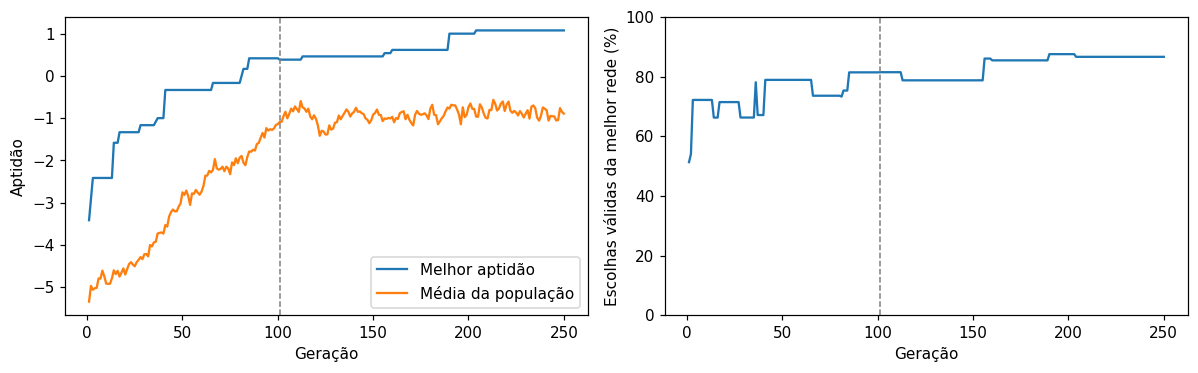

In [12]:
while not treinador.stopped:
    treinador.step()
    registrar_diversidade()
    if treinador.generation % 25 == 0:
        ultima = treinador.history[-1]
        print(f'Geração {treinador.generation}: aptidão {ultima["best"]:.3f}, fase {ultima["phase"]}')
print("Treino encerrado:", treinador.stopped)
mostrar_evolucao(treinador.history, "genetico_evolucao.png")

## Resultados durante o treino

O gráfico usa a melhor rede de cada geração. As quantidades de partidas mudam quando o difícil entra, então mostramos proporções de vitórias, empates e derrotas. A linha pontilhada indica a mudança de fase.

No outro gráfico olhamos a diversidade dos pesos. Uma população mais parecida não significa automaticamente que aprendeu o jogo.

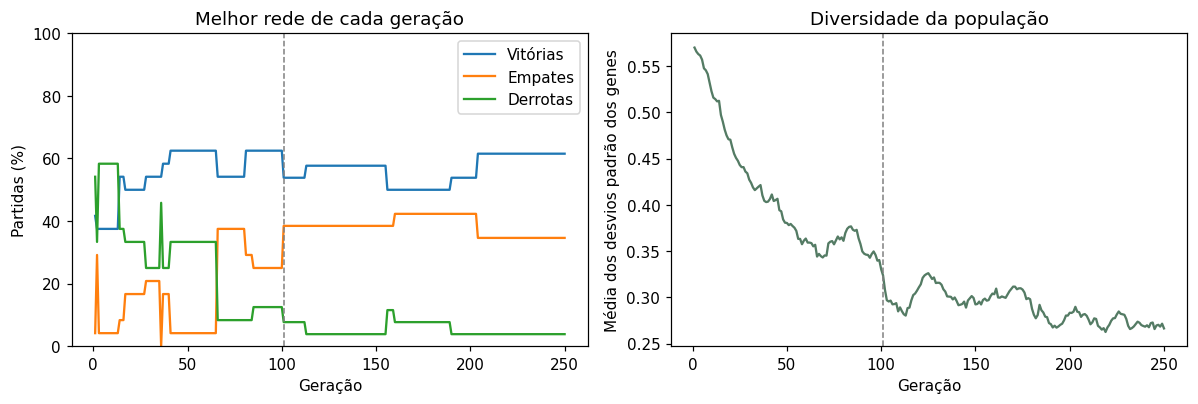

In [13]:
geracoes = [h["generation"] for h in treinador.history]
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8))
for chave, nome in [("vitoria", "Vitórias"), ("empate", "Empates"), ("derrota", "Derrotas")]:
    proporcoes = [100*h[chave]/(h["vitoria"]+h["empate"]+h["derrota"]) for h in treinador.history]
    eixos[0].plot(geracoes, proporcoes, label=nome)
eixos[0].set(title="Melhor rede de cada geração", xlabel="Geração", ylabel="Partidas (%)", ylim=(0, 100))
eixos[0].legend()
eixos[1].plot([d["generation"] for d in diversidade], [d["dispersion"] for d in diversidade], color="#547b64")
eixos[1].set(title="Diversidade da população", xlabel="Geração", ylabel="Média dos desvios padrão dos genes")
inicio_dificil = next((h["generation"] for h in treinador.history if h["phase"] == "medio+dificil"), None)
if inicio_dificil is not None:
    for eixo in eixos:
        eixo.axvline(inicio_dificil, color="gray", linestyle="--", linewidth=1)
fig.tight_layout()
salvar_grafico(fig, "genetico_partidas_diversidade.png")
plt.show()
plt.close(fig)

## População ao final

Aqui aparecem as aptidões de todos os indivíduos da última geração e como elas se distribuem. A tabela mostra os primeiros colocados. São resultados do conjunto de treino, não do teste reservado.

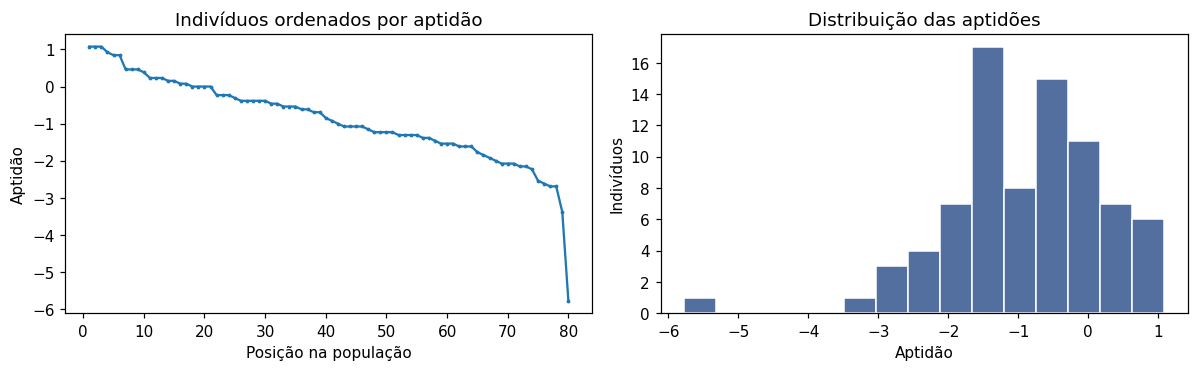

Posição,Aptidão,Vitórias,Empates,Derrotas,Inválidas
1,1.0769230769230769,16,9,1,13
2,1.0769230769230769,16,9,1,13
3,1.0769230769230769,13,13,0,12
4,0.9230769230769231,15,9,2,12
5,0.8461538461538461,13,12,1,13
6,0.8461538461538461,15,9,2,13
7,0.46153846153846156,13,12,1,18
8,0.46153846153846156,15,7,4,14
9,0.46153846153846156,15,9,2,18
10,0.38461538461538464,15,8,3,17


In [14]:
aptidoes = [r["fitness"] for r in treinador.ranked]
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.5))
eixos[0].plot(range(1, len(aptidoes)+1), aptidoes, marker=".", markersize=3)
eixos[0].set(title="Indivíduos ordenados por aptidão", xlabel="Posição na população", ylabel="Aptidão")
eixos[1].hist(aptidoes, bins=min(15, len(aptidoes)), color="#526fa0", edgecolor="white")
eixos[1].set(title="Distribuição das aptidões", xlabel="Aptidão", ylabel="Indivíduos")
fig.tight_layout()
salvar_grafico(fig, "genetico_populacao.png")
plt.show()
plt.close(fig)
mostrar_tabela(["Posição", "Aptidão", "Vitórias", "Empates", "Derrotas", "Inválidas"], [
    [i+1, r["fitness"], r["vitoria"], r["empate"], r["derrota"], r["invalid"]]
    for i, r in enumerate(treinador.ranked[:10])
])

## Teste da rede treinada

Usamos as sementes reservadas, fora da seleção do AG. A acurácia conta as escolhas originais que pertencem ao conjunto de ações ótimas do Minimax, divididas pelas decisões da rede. Uma escolha ocupada conta como erro.

Vitórias, empates e derrotas ficam separados. No difícil, são duas partidas determinísticas, uma para cada jogador inicial. Isso não cobre todas as sequências possíveis de jogadas ótimas.

In [15]:
avaliacao_final = {
    "medium": evaluate(treinador.best, 100, False, 1000000, True),
    "hard": evaluate(treinador.best, 0, True, 2000000, True),
}
mostrar_tabela(["Modo", "Partidas", "Vitórias", "Empates", "Derrotas", "Inválidas", "Acurácia"], [
    [modo, r["games"], r["vitoria"], r["empate"], r["derrota"], r["invalid"], f'{100*r["accuracy"]:.1f}%']
    for modo, r in avaliacao_final.items()
])

Modo,Partidas,Vitórias,Empates,Derrotas,Inválidas,Acurácia
medium,100,64,21,15,62,77.9%
hard,2,0,2,0,1,88.9%


## Primeira e última geração no mesmo teste

A comparação usa a melhor rede da primeira geração e a melhor da última, nas mesmas partidas reservadas do modo médio. Assim podemos olhar a mudança fora do conjunto usado na seleção. A rede da primeira geração já é a melhor entre os indivíduos iniciais, não uma rede aleatória qualquer.

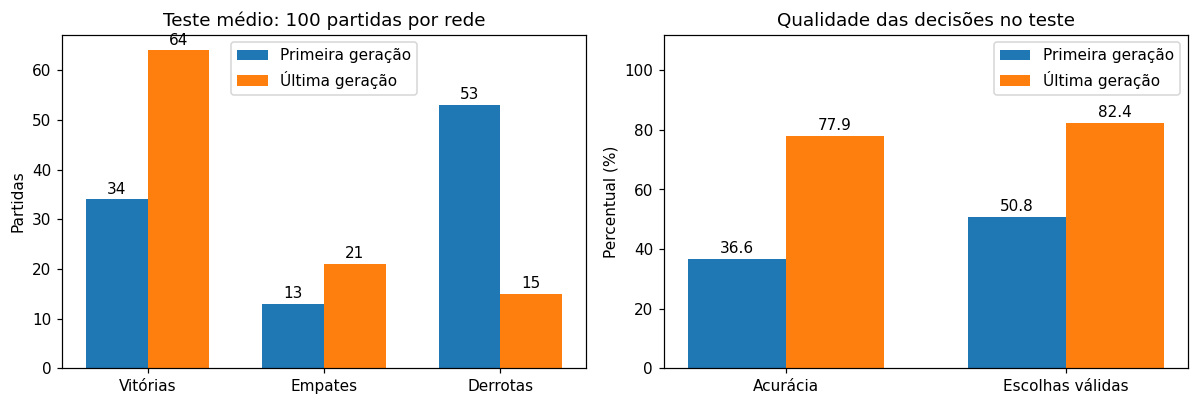

In [16]:
comparacao_ag = {"Primeira geração": avaliacao_inicial["medium"], "Última geração": avaliacao_final["medium"]}
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(3)
for i, (nome, r) in enumerate(comparacao_ag.items()):
    barras = eixos[0].bar(x+(i-0.5)*0.35, [r["vitoria"], r["empate"], r["derrota"]], 0.35, label=nome)
    eixos[0].bar_label(barras, padding=2)
eixos[0].set(title="Teste médio: 100 partidas por rede", ylabel="Partidas", xticks=x, xticklabels=["Vitórias", "Empates", "Derrotas"])
eixos[0].legend()
x = np.arange(2)
for i, (nome, r) in enumerate(comparacao_ag.items()):
    barras = eixos[1].bar(x+(i-0.5)*0.35, [100*r["accuracy"], 100*r["valid_rate"]], 0.35, label=nome)
    eixos[1].bar_label(barras, fmt="%.1f", padding=2)
eixos[1].set(title="Qualidade das decisões no teste", ylabel="Percentual (%)", ylim=(0, 112), xticks=x, xticklabels=["Acurácia", "Escolhas válidas"])
eixos[1].legend()
fig.tight_layout()
salvar_grafico(fig, "genetico_comparativo.png")
plt.show()
plt.close(fig)

## Uma partida, jogada por jogada

Aqui podemos mudar o modo do adversário e quem começa. A tabela permite conferir a escolha original da rede, a casa usada e a recompensa registrada. As casas são mostradas a partir de 1 para facilitar a leitura.

In [17]:
modo = "dificil"
rede_comeca = True
partida = play(treinador.best, modo, rede_comeca, 1000000, trace=True, measure=True)
mostrar_tabela(["Jogada", "Jogador", "Escolha original", "Casa executada", "Recompensa"], [
    [i+1, e["actor"], e["raw"]+1 if e["raw"] is not None else "—", e["move"]+1, e["reward"]]
    for i, e in enumerate(partida["events"])
])
print("Resultado para a rede:", partida["outcome"])
print("Escolhas inválidas:", partida["invalid"])
print("Pontuação da partida:", partida["score"])

Jogada,Jogador,Escolha original,Casa executada,Recompensa
1,rede,5,5,0.0
2,minimax,—,1,0.0
3,rede,3,3,0.0
4,minimax,—,7,0.0
5,rede,4,4,0.0
6,minimax,—,6,0.0
7,rede,9,9,0.0
8,minimax,—,2,0.0
9,rede,9,8,-1.0


Resultado para a rede: empate
Escolhas inválidas: 1
Pontuação da partida: -1.0


## Guardar o experimento do notebook

Os arquivos abaixo têm nomes próprios para não substituir a rede e a avaliação que já acompanham o relatório. Depois de executar esta célula, abra o jogo, clique em **Carregar rede** e escolha `t2/algoritmos/genetico/rede-notebook.json`.

In [18]:
pasta_saida = raiz / "t2" / "algoritmos" / "genetico"
pasta_saida.mkdir(parents=True, exist_ok=True)
rede_notebook = {
    "version": 1,
    "hidden": treinador.best.hidden,
    "weights": treinador.best.weights.tolist(),
    "config": asdict(config),
    "history": treinador.history,
}
relatorio_notebook = {
    "config": asdict(config),
    "generations": treinador.generation,
    "stop": treinador.stopped,
    "baseline": avaliacao_inicial,
    "final": avaliacao_final,
}
(pasta_saida / "rede-notebook.json").write_text(json.dumps(rede_notebook, ensure_ascii=False, indent=2))
(pasta_saida / "avaliacao-notebook.json").write_text(json.dumps(relatorio_notebook, ensure_ascii=False, indent=2))
print("Rede salva:", (pasta_saida / "rede-notebook.json").relative_to(raiz))
print("Avaliação salva:", (pasta_saida / "avaliacao-notebook.json").relative_to(raiz))

Rede salva: t2/algoritmos/genetico/rede-notebook.json
Avaliação salva: t2/algoritmos/genetico/avaliacao-notebook.json


## O que observar na análise

Compare o começo e o fim do treino, mas olhe também as escolhas inválidas. Se a rede ainda depende da recuperação para jogar em uma casa livre, isso precisa aparecer na explicação dos resultados.

Podemos variar a semente e a camada oculta para novos experimentos. Se os parâmetros forem escolhidos olhando repetidamente o mesmo teste, depois será preciso outra avaliação para conferir o resultado dessas escolhas.

## Arquivos na pasta do algoritmo

Os gráficos mostrados acima também são salvos em PNG nesta pasta. Os números vão para arquivos CSV, junto do código e do notebook, como no T1. Rodar as células novamente atualiza esses arquivos com a execução atual.


In [19]:
salvar_csv("genetico_evolucao.csv", treinador.history)
salvar_csv("genetico_diversidade.csv", diversidade)
salvar_csv("genetico_populacao_final.csv", [
    {"posicao": i+1, **r} for i, r in enumerate(treinador.ranked)
])
salvar_csv("genetico_resultados_teste.csv", [
    {"etapa": etapa, "modo": modo, **r}
    for etapa, avaliacao in [("Primeira geração", avaliacao_inicial), ("Última geração", avaliacao_final)]
    for modo, r in avaliacao.items()
])
print("Arquivos PNG e CSV em:", pasta_algoritmo.relative_to(raiz))


Arquivos PNG e CSV em: t2/algoritmos/genetico
